<a href="https://colab.research.google.com/github/Knjane/chatbot-/blob/main/housing_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Installing Python Libraries in Colab

You can install any Python library from PyPI using the `!pip install` command. The exclamation mark `!` tells Colab to run the line as a bash command rather than as Python code.
```

In [16]:
df = pd.read_csv("sample_data/california_housing_train.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv("sample_data/california_housing_train.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [ ]:
# Display summary statistics of the housing DataFrame
display(df.describe())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [ ]:
# Filter and display rows containing any missing (null) values
missing_rows = df[df.isnull().any(axis=1)]

print(f"Number of rows with missing values: {len(missing_rows)}")
if len(missing_rows) > 0:
    display(missing_rows)
else:
    print("There are no missing values in the dataset to display.")

Number of rows with missing values: 0
There are no missing values in the dataset to display.


In [ ]:
# Check for missing values in each column of the DataFrame
missing_values = df.isnull().sum()
print("Missing values per column:")
display(missing_values)

Missing values per column:


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0


In [ ]:
# Group the data by housing_median_age and find the mean of median_house_value
age_grouped_value = df.groupby('housing_median_age')['median_house_value'].mean().reset_index()

# Rename columns for clarity and display the resulting DataFrame
age_grouped_value.columns = ['housing_median_age', 'mean_median_house_value']
display(age_grouped_value)

,housing_median_age,mean_median_house_value
0,1.0,190250.000000
1,2.0,229438.836735
2,3.0,239450.043478
3,4.0,230054.105590
4,5.0,211035.708543
5,6.0,206768.240310
6,7.0,188445.059603
7,8.0,190805.073034
8,9.0,190306.994186
9,10.0,178416.393805


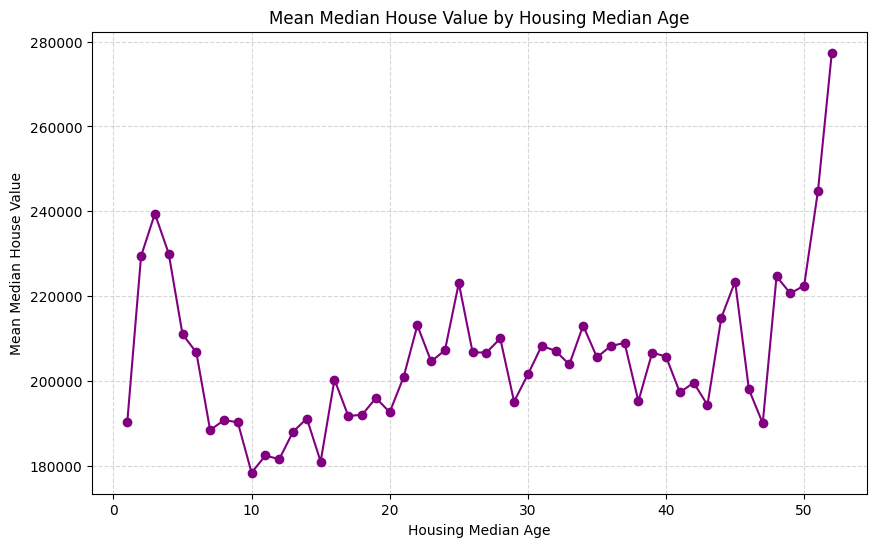

In [ ]:
import matplotlib.pyplot as plt

# Plot mean median_house_value by housing_median_age
plt.figure(figsize=(10, 6))
plt.plot(age_grouped_value['housing_median_age'], age_grouped_value['mean_median_house_value'], marker='o', color='purple', linestyle='-')
plt.title('Mean Median House Value by Housing Median Age')
plt.xlabel('Housing Median Age')
plt.ylabel('Mean Median House Value')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Find the row with the maximum mean_median_house_value
max_value_row = age_grouped_value.loc[age_grouped_value['mean_median_house_value'].idxmax()]

print(f"Housing Median Age with highest mean house value: {max_value_row['housing_median_age']:.0f} years")
print(f"Highest Mean Median House Value: ${max_value_row['mean_median_house_value']:.2f}")

Housing Median Age with highest mean house value: 52 years
Highest Mean Median House Value: $277368.20


In [ ]:
# Calculate the correlation between median_income and median_house_value
correlation = df['median_income'].corr(df['median_house_value'])
print(f"Correlation between median_income and median_house_value: {correlation:.4f}")

Correlation between median_income and median_house_value: 0.6919


In [ ]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Define the independent variable (X) and dependent variable (y)
X = df['median_income']
y = df['median_house_value']

# Add a constant (intercept) to the independent variable
X_const = sm.add_constant(X)

# Fit the ordinary least squares (OLS) model
model = sm.OLS(y, X_const).fit()

# Print the regression results summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.479
Model:                            OLS   Adj. R-squared:                  0.479
Method:                 Least Squares   F-statistic:                 1.561e+04
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:06:18   Log-Likelihood:            -2.1683e+05
No. Observations:               17000   AIC:                         4.337e+05
Df Residuals:                   16998   BIC:                         4.337e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          4.398e+04   1456.540     30.195

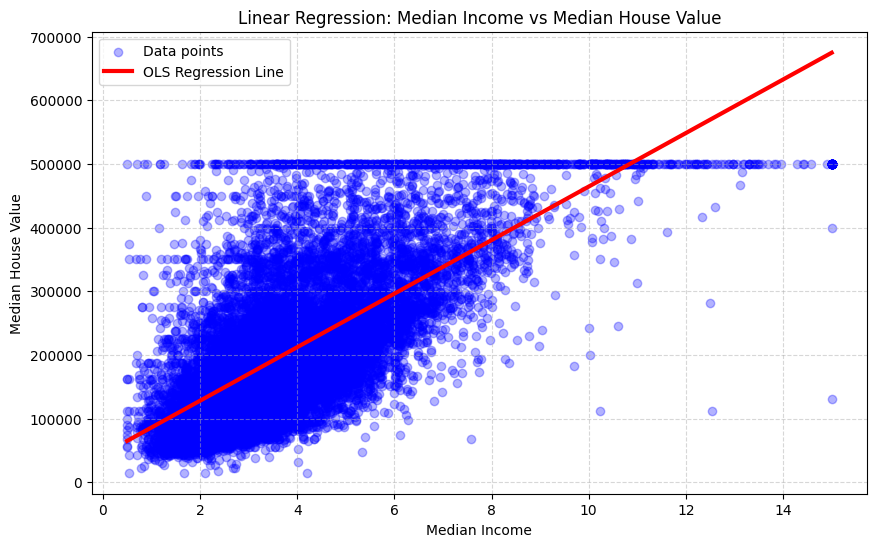

In [ ]:
# Plot the regression line
plt.figure(figsize=(10, 6))
plt.scatter(df['median_income'], df['median_house_value'], alpha=0.3, label='Data points', color='blue')

# Generate predictions for the plot
X_plot = np.linspace(df['median_income'].min(), df['median_income'].max(), 100)
X_plot_const = sm.add_constant(X_plot)
y_plot = model.predict(X_plot_const)

plt.plot(X_plot, y_plot, color='red', linewidth=3, label='OLS Regression Line')
plt.title('Linear Regression: Median Income vs Median House Value')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Calculate correlation of all features with the target variable
correlations = df.corr()['median_house_value'].sort_values(ascending=False)
print("Correlation of all features with median_house_value:")
print(correlations)

Correlation of all features with median_house_value:
median_house_value    1.000000
median_income         0.691871
total_rooms           0.130991
housing_median_age    0.106758
households            0.061031
total_bedrooms        0.045783
population           -0.027850
longitude            -0.044982
latitude             -0.144917
Name: median_house_value, dtype: float64


In [ ]:
# Define multiple independent variables (excluding the target column)
X_all = df.drop(columns=['median_house_value'])
y_all = df['median_house_value']

# Add constant to the variables
X_all_const = sm.add_constant(X_all)

# Fit the multiple linear regression model
multiple_model = sm.OLS(y_all, X_all_const).fit()

# Print the summary to see the improved R-squared value
print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.641
Model:                            OLS   Adj. R-squared:                  0.641
Method:                 Least Squares   F-statistic:                     3798.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:08:10   Log-Likelihood:            -2.1365e+05
No. Observations:               17000   AIC:                         4.273e+05
Df Residuals:                   16991   BIC:                         4.274e+05
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -3.621e+06   6.92

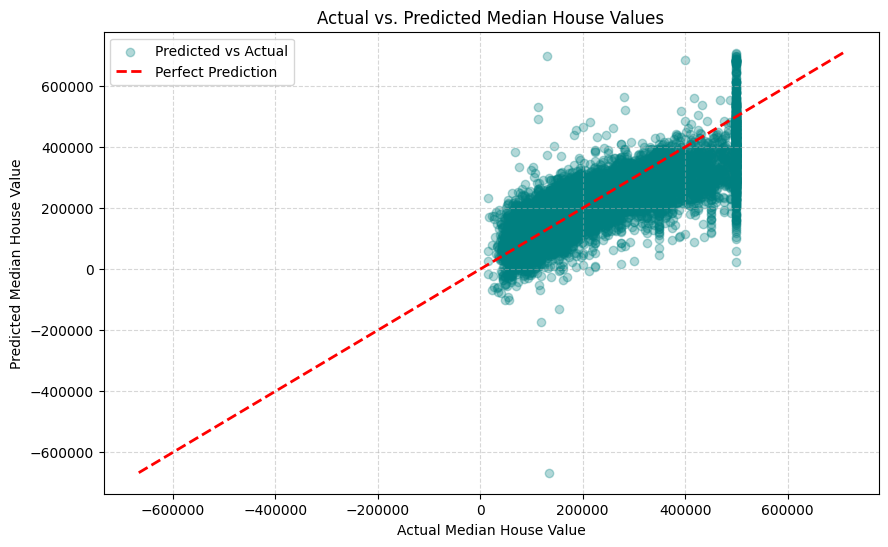

In [ ]:
# Generate predictions using the multiple regression model
y_pred = multiple_model.predict(X_all_const)

# Plot Actual vs Predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_all, y_pred, alpha=0.3, color='teal', label='Predicted vs Actual')

# Draw a diagonal reference line (y = x) representing a perfect model prediction
min_val = min(y_all.min(), y_pred.min())
max_val = max(y_all.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

plt.title('Actual vs. Predicted Median House Values')
plt.xlabel('Actual Median House Value')
plt.ylabel('Predicted Median House Value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Define features (X) and target (y)
X_model = df.drop(columns=['median_house_value'])
y_model = df['median_house_value']

# Split the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X_model, y_model, test_size=0.2, random_state=42)

# Initialize and train the Linear Regression model
reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_test = reg_model.predict(X_test)

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)

print(f"Model Training Completed Successfully!")
print(f"Test R-squared (R2): {r2:.4f}")
print(f"Test Root Mean Squared Error (RMSE): ${rmse:.2f}")

Model Training Completed Successfully!
Test R-squared (R2): 0.6636
Test Root Mean Squared Error (RMSE): $68078.33


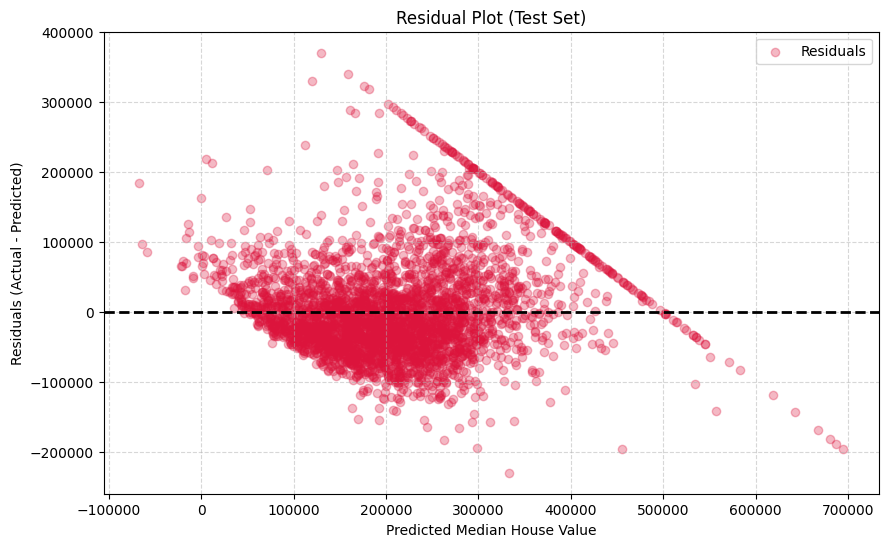

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate residuals
residuals = y_test - y_pred_test

# Create the residual plot
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_test, residuals, alpha=0.3, color='crimson', label='Residuals')

# Add a horizontal line at y=0 representing perfect predictions
plt.axhline(y=0, color='black', linestyle='--', linewidth=2)

plt.title('Residual Plot (Test Set)')
plt.xlabel('Predicted Median House Value')
plt.ylabel('Residuals (Actual - Predicted)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Define features (X) and target (y) from the active dataframe
X_model = df.drop(columns=['median_house_value'])
y_model = df['median_house_value']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X_model, y_model, test_size=0.2, random_state=42)

# Initialize and train the RandomForestRegressor model
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


In [5]:
from sklearn.metrics import mean_absolute_error

predictions = model.predict(X_test)
MAE = mean_absolute_error(y_test, predictions)
print(MAE, round(MAE, 2))

Mean Absolute Error: 32359.79
